# Correlation of seasonal drivers with seasonal FP

For each perennial camera, this correlates each driver's seasonal aggregate in each season with FP's seasonal mean in each season: 5 drivers × 4 seasons × 4 FP seasons at each camera. Each correlation is across water years.

**Timing.** Seasons in a water year run PMR, CSR, PMD, MSN. A driver season later in the water year than the FP season is taken from the previous water year, so a driver never comes after the FP it is paired with. Set `lag_later_seasons = False` to pair everything within the same water year.

**Correlation.** Spearman, because FP is bounded and has many ties at 1. `p_adj` is BH across all tests at a camera.

| Column | Meaning |
|---|---|
| `rho`, `p`, `p_adj`, `n` | Main result, using gap-filled FP |
| `rho_detrended` | Both series linearly detrended first, so a shared long-term trend can't produce the correlation |
| `rho_observed` | FP from observed days only |

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests

In [20]:
sites = {"Fairbank": 1, "CharlestonMesquite": 2, "Hunter": 4, "Contention": 6, "St.David": 7}
site_names = {1: "Fairbank", 2: "Charleston Mesquite", 4: "Hunter", 6: "Contention", 7: "St. David"}
seasons = {"PMR": 4, "CSR": 1, "PMD": 2, "MSN": 3}
drivers = {"precip": "P", "temp": "T", "vpd": "VPD", "et": "ET", "gw": "GW"}

start_wy, end_wy = 2006, 2025
min_n = 8
alpha = 0.05
lag_later_seasons = True

def season(month):
    if month in [12, 1, 2, 3]:
        return 1
    if month in [4, 5, 6]:
        return 2
    if month in [7, 8, 9]:
        return 3
    return 4

def add_period(df):
    df = df.copy()
    df["WY"] = df["date"].dt.year + (df["date"].dt.month >= 10)
    df["Season"] = df["date"].dt.month.map(season)
    return df

calendar = add_period(pd.DataFrame({"date": pd.date_range(f"{start_wy - 1}-10-01", f"{end_wy}-09-30")}))
season_days = calendar.groupby(["WY", "Season"]).agg(expected = ("date", "size"), season_end = ("date", "max")).reset_index()

def seasonal_aggregate(daily, statistic, complete_through = None):
    out = (
        add_period(daily.dropna(subset = ["value"]))
        .groupby(["Camera", "WY", "Season"])["value"].agg([("value", {"mean": "mean", "total": "sum", "min": "min"}[statistic]), ("size", "size")]).reset_index()
        .merge(season_days, on = ["WY", "Season"])
    )
    out = out[out["WY"].between(start_wy, end_wy)]
    if statistic == "total": # scale up by the fraction of days missing, so a partial season isn't undercounted
        out["value"] = out["value"] * out["expected"] / out["size"]
    if complete_through is not None:
        out = out[out["season_end"] <= complete_through]
    return out[["Camera", "WY", "Season", "value"]].rename(columns = {"value": "mean"})

In [21]:
gf = pd.read_csv("../Data/SPRNCAPredFP.csv", parse_dates = ["date"])
gf["Camera"] = gf["site"].map(sites)
gf = gf.dropna(subset = ["Camera"]).astype({"Camera": int})

fp = seasonal_aggregate(gf.assign(value = gf["fp_final"]), "mean")
fp_observed = seasonal_aggregate(gf.assign(value = gf["fp_final"].where(gf["source"] == "observed")), "mean")

daymet = pd.read_csv("../Data/Daymet2006_2025.csv")
daymet["date"] = pd.to_datetime(daymet["date"], format = "%m/%d/%Y")
daymet = daymet[daymet["camera"].isin(sites.values())].rename(columns = {"camera": "Camera"})

def load_nagler():
    raw = pd.read_csv("../Data/ET/NaglerET.csv", header = None, skiprows = 7)
    columns = {"Fairbank": (3, 36), "CharlestonMesquite": (3, 24), "Hunter": (3, 12), "Contention": (54, 57), "St.David": (54, 63)}
    series = []
    for site, (date_col, et_col) in columns.items():
        s = raw[[date_col, et_col]].copy()
        s.columns = ["date", "value"]
        s["date"] = pd.to_datetime(s["date"], format = "mixed", errors = "coerce")
        s["value"] = pd.to_numeric(s["value"], errors = "coerce")
        s = s.dropna().sort_values("date")
        days = pd.DataFrame({"date": pd.date_range(s["date"].min() - pd.Timedelta(days = 8), s["date"].max() + pd.Timedelta(days = 8))})
        midpoints = s["date"].iloc[:-1].to_numpy() + (s["date"].iloc[1:].to_numpy() - s["date"].iloc[:-1].to_numpy()) / 2
        days["value"] = s["value"].to_numpy()[np.searchsorted(midpoints, days["date"].to_numpy(), side = "right")] # each day takes the nearest composite, as in PermutationCPD.R
        series.append(days.assign(Camera = sites[site]))
    return pd.concat(series, ignore_index = True)

gw = pd.read_csv("../Data/GW/CamSPRNCA_GW.csv", parse_dates = ["datetime"])
gw = gw[gw["camera"].isin(sites.values())]
gw = pd.DataFrame({"Camera": gw["camera"], "date": gw["datetime"].dt.normalize(), "value": gw["height_abv_lowest_ft"] * 304.8})

driver_means = { # same aggregation as the CPD figures (PermutationCPD.R)
    "precip": seasonal_aggregate(daymet.assign(value = daymet["prcp"]), "total"),
    "temp": seasonal_aggregate(daymet.assign(value = (daymet["tmax"] + daymet["tmin"]) / 2), "mean"),
    "vpd": seasonal_aggregate(daymet.assign(value = daymet["tvpd"]), "mean"),
    "et": seasonal_aggregate(load_nagler(), "total"),
    "gw": seasonal_aggregate(gw, "min", complete_through = gw["date"].max()),
}

In [22]:
def get_series(df, camera, season_name):
    return df[(df["Camera"] == camera) & (df["Season"] == seasons[season_name])].set_index("WY")["mean"]

def spearman(x, y):
    if len(x) < min_n or x.nunique() < 2 or y.nunique() < 2:
        return np.nan, np.nan
    return stats.spearmanr(x, y)

def detrend(s):
    return s - np.polyval(np.polyfit(s.index, s.to_numpy(), 1), s.index)

def pair(x, y):
    joined = pd.concat([x, y], axis = 1, join = "inner", keys = ["x", "y"])
    return joined["x"], joined["y"]

order = list(seasons)
rows = []
for camera in sites.values():
    for driver in drivers:
        for fp_season in order:
            for driver_season in order:
                lag = int(lag_later_seasons and order.index(driver_season) > order.index(fp_season))
                x = get_series(driver_means[driver], camera, driver_season)
                x.index = x.index + lag

                x_fp, y_fp = pair(x, get_series(fp, camera, fp_season))
                rho, p = spearman(x_fp, y_fp)
                enough = len(x_fp) >= min_n and y_fp.nunique() >= 2
                rho_detrended = spearman(detrend(x_fp), detrend(y_fp))[0] if enough else np.nan
                rho_observed = spearman(*pair(x, get_series(fp_observed, camera, fp_season)))[0]

                rows.append({
                    "Camera": camera, "driver": drivers[driver], "fp_season": fp_season, "driver_season": driver_season,
                    "lag_wy": lag, "n": len(x_fp), "rho": rho, "p": p, "rho_detrended": rho_detrended, "rho_observed": rho_observed,
                })

correlations = pd.DataFrame(rows)
correlations["p_adj"] = np.nan
for camera, group in correlations.dropna(subset = ["p"]).groupby("Camera"):
    correlations.loc[group.index, "p_adj"] = multipletests(group["p"], method = "fdr_bh")[1]
correlations.to_csv("../Data/fp_driver_correlations.csv", index = False)

summary = correlations.groupby("Camera").agg(tests = ("p", "count"), p_under_05 = ("p", lambda p: (p < alpha).sum()), p_adj_under_05 = ("p_adj", lambda p: (p < alpha).sum()))
summary

,tests,p_under_05,p_adj_under_05
Camera,,,
1,80,30,22
2,60,15,9
4,78,10,0
6,76,22,11
7,64,22,16


In [23]:
significant = correlations[correlations["p_adj"] < alpha].copy()
significant["abs_rho"] = significant["rho"].abs()
significant = significant.sort_values(["Camera", "fp_season", "abs_rho"], ascending = [True, True, False]).drop(columns = "abs_rho")
significant.round(3)

,Camera,driver,fp_season,driver_season,lag_wy,n,rho,p,rho_detrended,rho_observed,p_adj
23,1,T,CSR,MSN,1,19,-0.627,0.004,-0.537,-0.627,0.025
69,1,GW,CSR,CSR,0,18,0.624,0.006,0.682,0.624,0.032
7,1,P,CSR,MSN,1,19,0.598,0.007,0.558,0.598,0.032
39,1,VPD,CSR,MSN,1,19,-0.598,0.007,-0.588,-0.598,0.032
53,1,ET,CSR,CSR,0,20,-0.576,0.008,-0.650,-0.586,0.035
36,1,VPD,CSR,PMR,0,19,-0.572,0.011,-0.667,-0.572,0.040
52,1,ET,CSR,PMR,0,20,-0.571,0.009,-0.445,-0.580,0.036
15,1,P,MSN,MSN,0,20,0.742,0.000,0.635,0.674,0.004
47,1,VPD,MSN,MSN,0,20,-0.719,0.000,-0.785,-0.531,0.005
31,1,T,MSN,MSN,0,20,-0.650,0.002,-0.611,-0.450,0.014


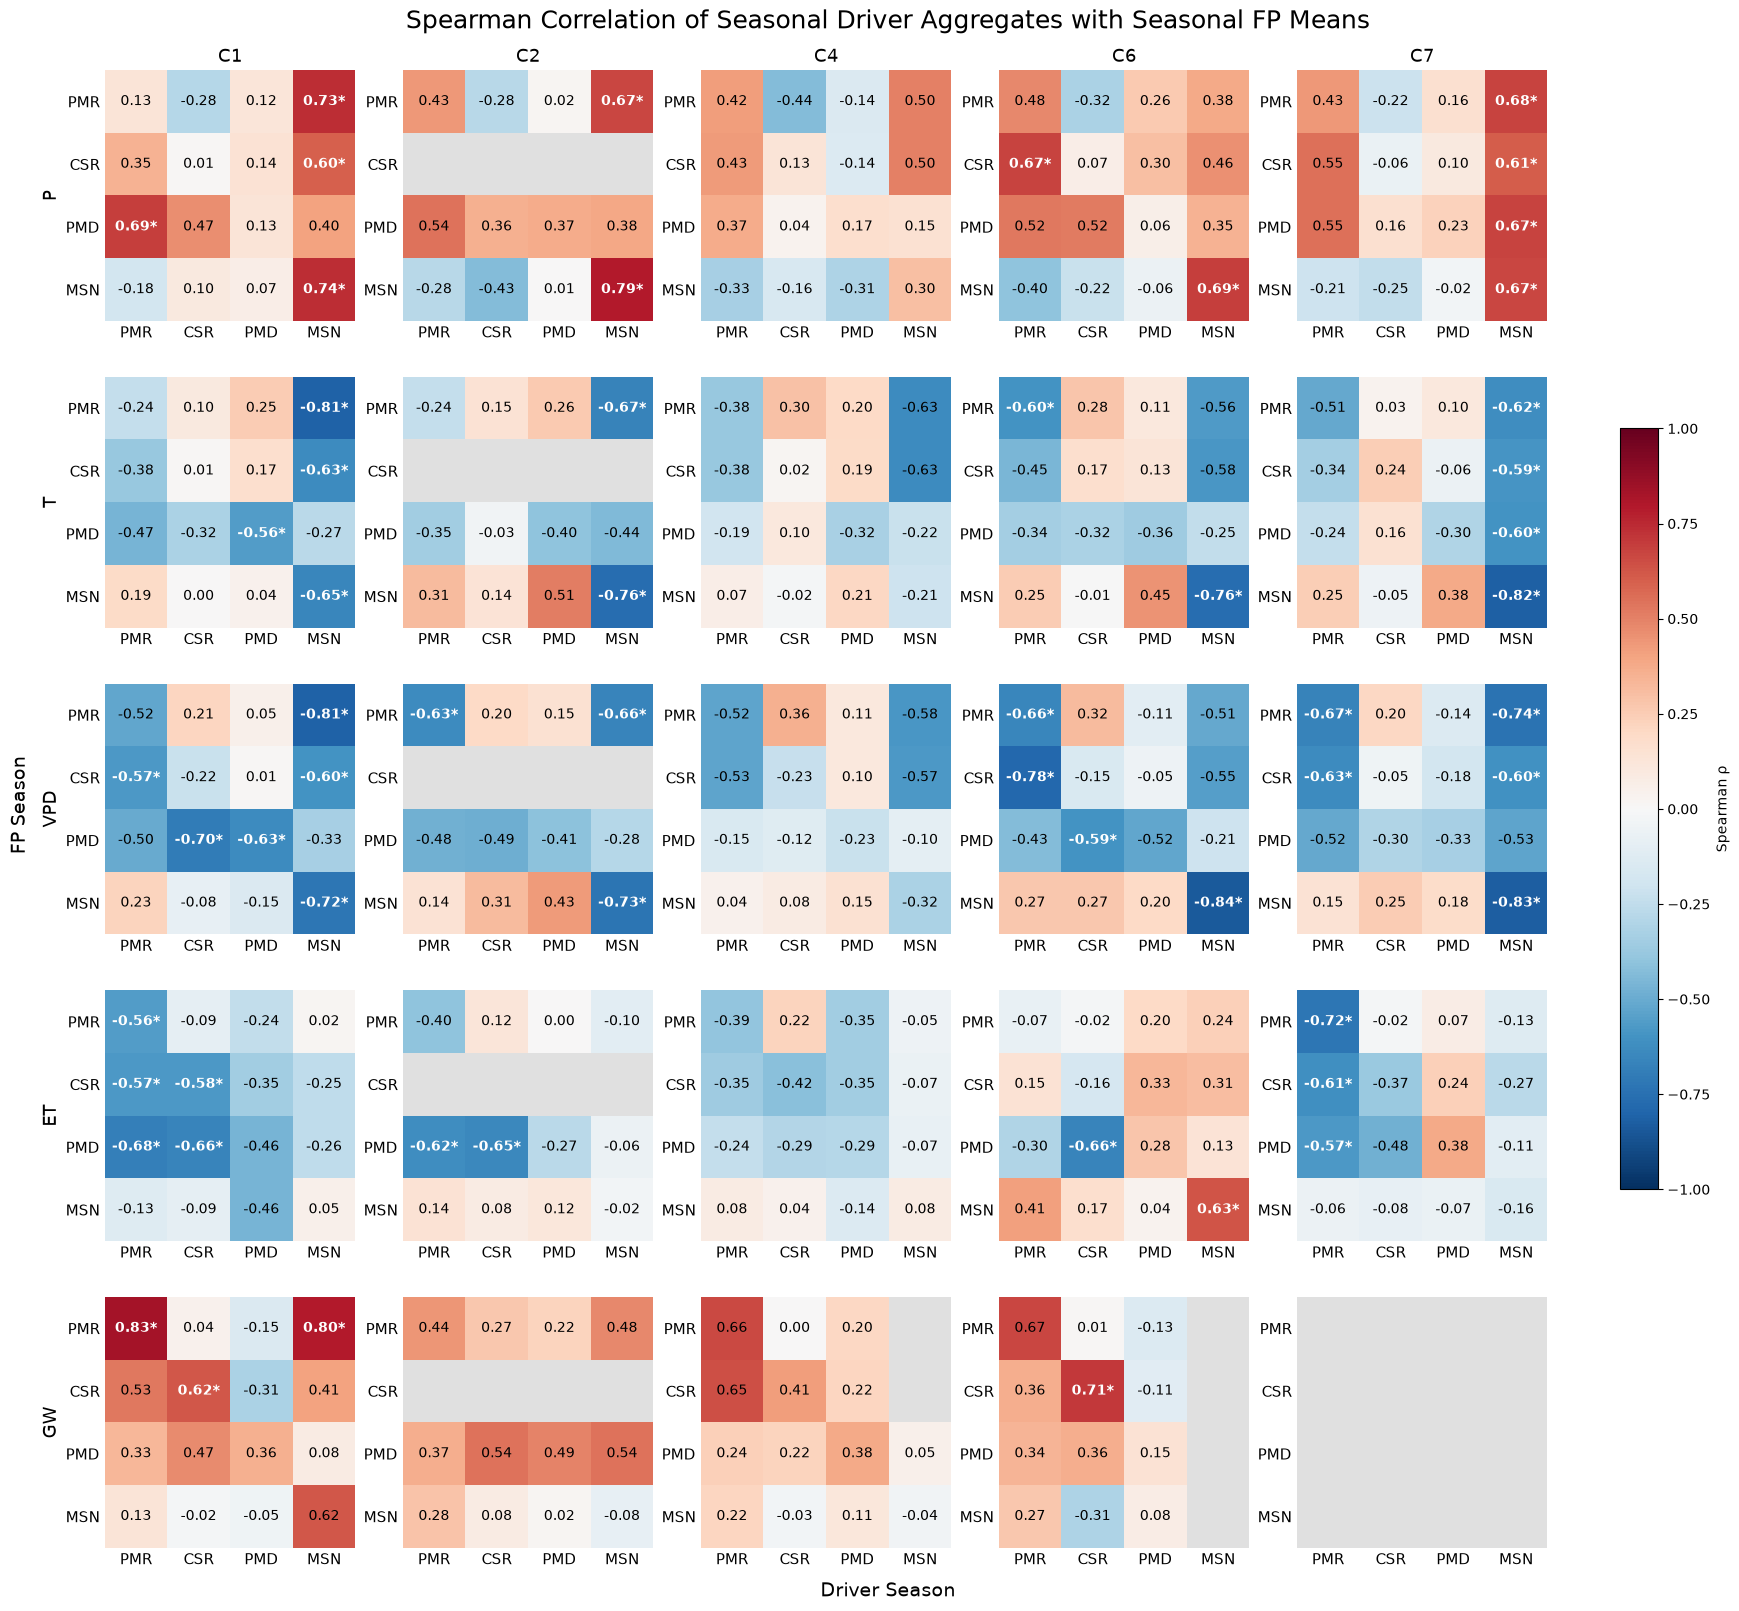

In [ ]:
fig, axes = plt.subplots(len(drivers), len(sites), figsize = (17, 16), sharex = True, sharey = True, constrained_layout = True)

for i, driver in enumerate(drivers.values()):
    for j, camera in enumerate(sites.values()):
        ax = axes[i, j]
        cells = correlations[(correlations["Camera"] == camera) & (correlations["driver"] == driver)]
        rho = cells.pivot(index = "fp_season", columns = "driver_season", values = "rho").loc[order, order]
        p_adj = cells.pivot(index = "fp_season", columns = "driver_season", values = "p_adj").loc[order, order]
        ax.set_facecolor("0.88")
        image = ax.imshow(rho, cmap = "RdBu_r", vmin = -1, vmax = 1)
        for r in range(4):
            for c in range(4):
                value = rho.iloc[r, c]
                if np.isnan(value):
                    continue
                star = p_adj.iloc[r, c] < alpha
                ax.text(c, r, f"{value:.2f}" + ("*" if star else ""), ha = "center", va = "center", fontsize = 10, fontweight = "bold" if star else "normal", color = "white" if star else "black")
        ax.set_xticks(range(4), order)
        ax.set_yticks(range(4), order)
        ax.tick_params(length = 0, labelsize = 11, labelbottom = True, labelleft = True)
        for spine in ax.spines.values():
            spine.set_visible(False)
        if i == 0:
            ax.set_title(f"C{camera}", fontsize = 13)
        if j == 0:
            ax.set_ylabel(driver, fontsize = 13)

fig.supxlabel("Driver Season", fontsize = 14)
fig.text(-0.005, 0.5, "FP Season", rotation = 90, ha = "right", va = "center", fontsize = 14)
fig.suptitle("Spearman Correlations of Seasonal Driver Aggregates with Seasonal FP Means", fontsize = 18)
fig.colorbar(image, ax = axes, shrink = 0.5, label = "Spearman ρ")
fig.savefig("../Figures/fp_driver_correlation.png", dpi = 300, bbox_inches = "tight")

In [25]:
checks = correlations.dropna(subset = ["rho"])
pd.DataFrame({
    "r with detrended rho": checks.groupby("Camera").apply(lambda g: g["rho"].corr(g["rho_detrended"]), include_groups = False),
    "r with observed-only rho": checks.groupby("Camera").apply(lambda g: g["rho"].corr(g["rho_observed"]), include_groups = False),
}).round(2)

,r with detrended rho,r with observed-only rho
Camera,,
1,0.93,0.96
2,0.93,0.94
4,0.79,0.97
6,0.95,0.97
7,0.96,0.98
